In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
tips.shape
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


## 3. Research Questions

1. How are restaurant bills distributed among customers?
2. How do tip amounts vary across different days?
3. Is there a relationship between the total bill and tip amount?
4. Which numerical variables have the strongest correlations?

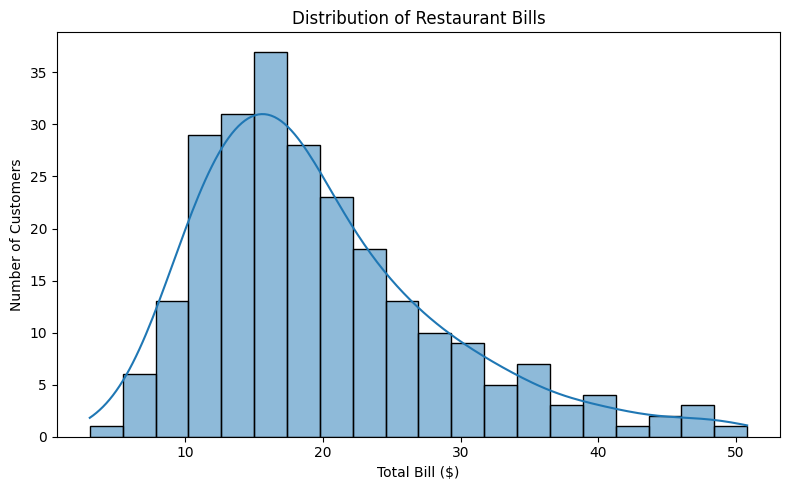

In [4]:
plt.figure(figsize=(8, 5))

sns.histplot(data=tips, x="total_bill", bins=20, kde=True)

plt.title("Distribution of Restaurant Bills")
plt.xlabel("Total Bill ($)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

**Key Insight:** Most restaurant bills are concentrated between $10 and $25, with the highest frequency around $15–$20. The distribution is right-skewed, indicating that relatively few customers have much higher bills.

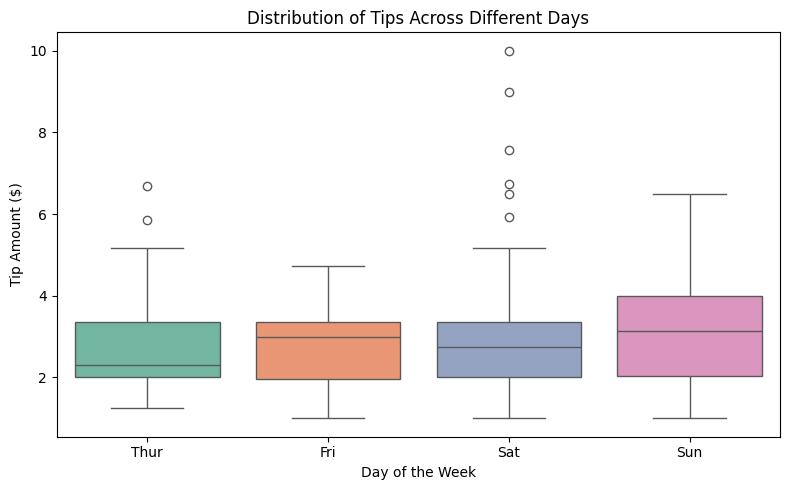

In [5]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=tips, x="day", y="tip", hue="day", palette="Set2", legend=False)

plt.title("Distribution of Tips Across Different Days")
plt.xlabel("Day of the Week")
plt.ylabel("Tip Amount ($)")

plt.tight_layout()
plt.show()

**Key Insight:** Friday has the highest median tip among the four days, while Saturday shows several high-tip outliers. Tip amounts vary across days, with some customers leaving considerably larger tips than others.

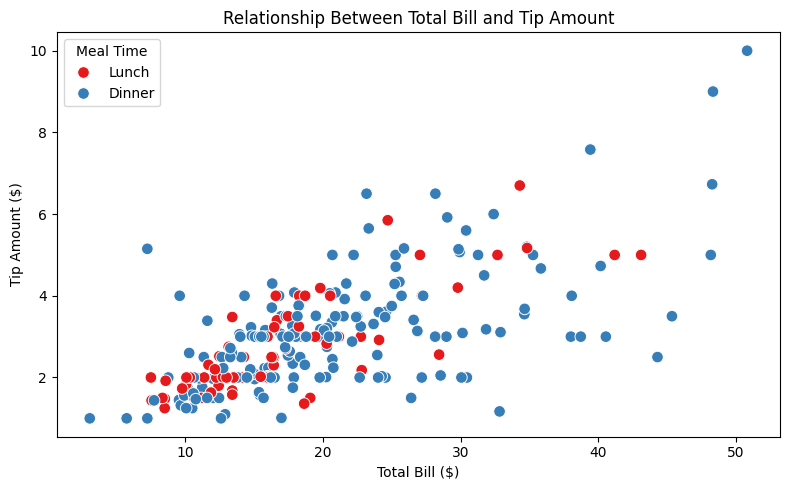

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    palette="Set1",
    s=70
)

plt.title("Relationship Between Total Bill and Tip Amount")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip Amount ($)")
plt.legend(title="Meal Time")

plt.tight_layout()
plt.show()

**Key Insight:** Total bill and tip amount show a positive relationship, meaning customers generally leave higher tips when their bills are larger. However, tip amounts still vary among customers with similar bills.

In [7]:
correlation = tips[["total_bill", "tip", "size"]].corr()

correlation

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


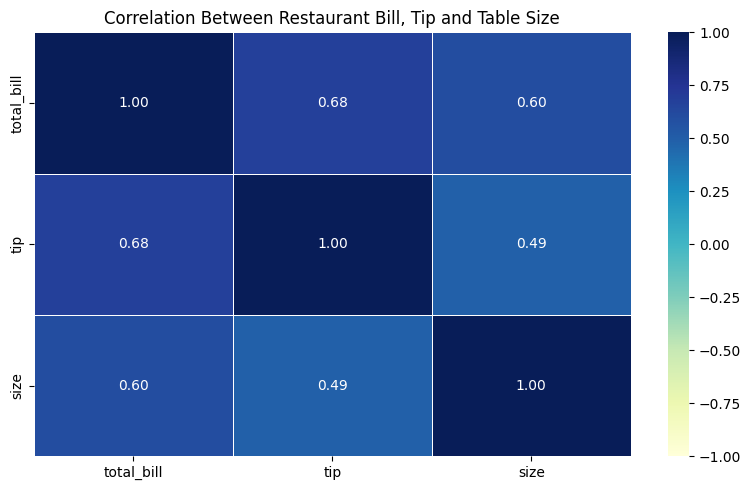

In [8]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Restaurant Bill, Tip and Table Size")

plt.tight_layout()
plt.show()

**Key Insight:** Total bill and tip have the strongest positive correlation (0.68), suggesting that larger restaurant bills are generally associated with higher tips. Table size also has positive correlations with both total bill (0.60) and tip (0.49).

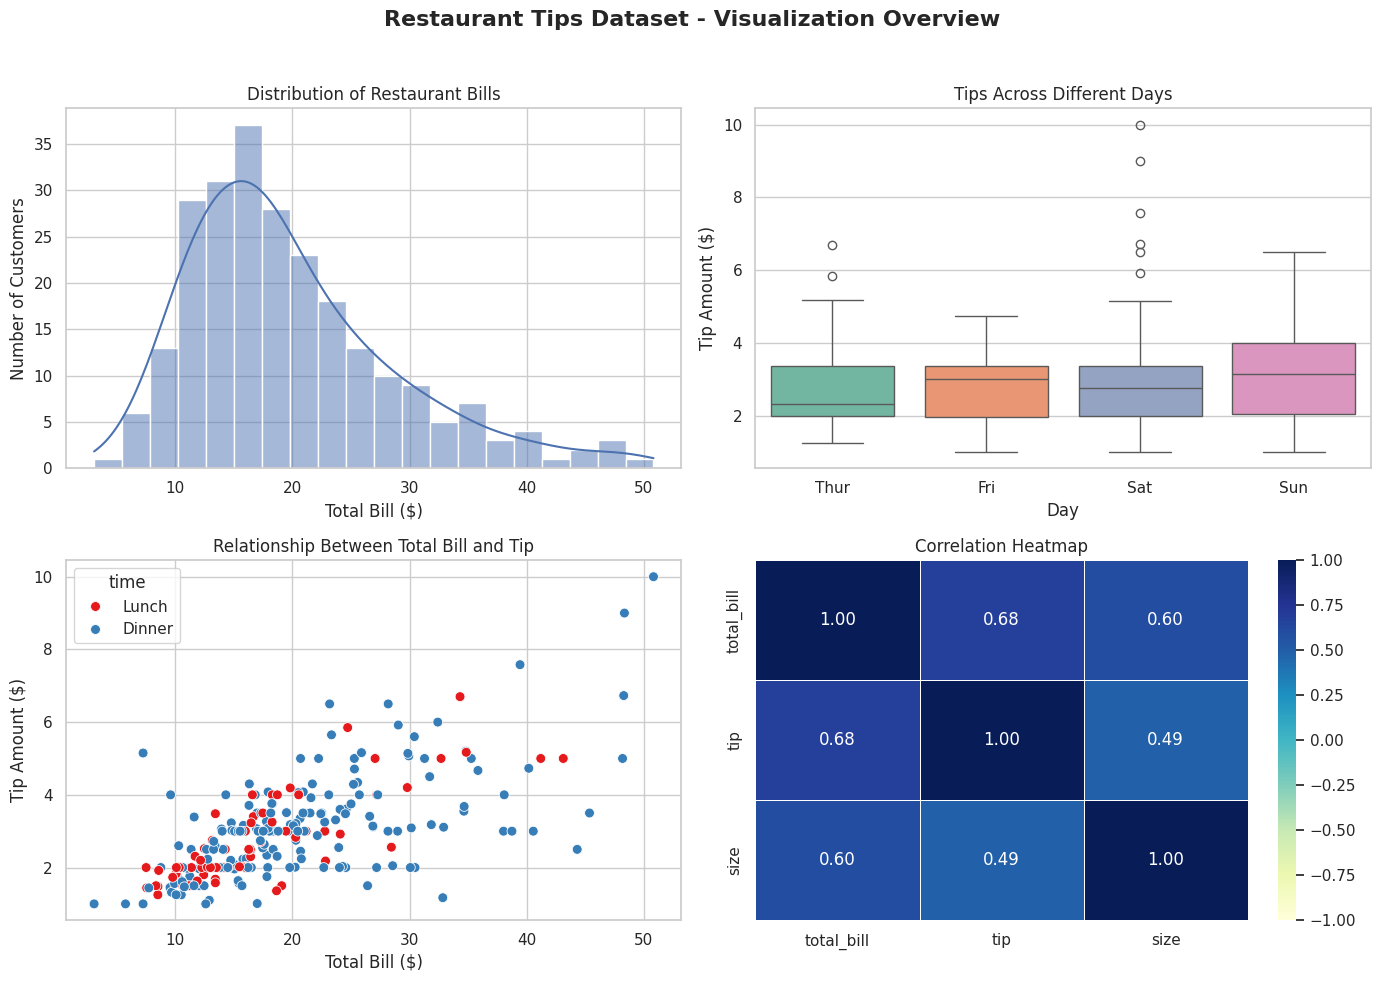

In [9]:

# Close any previously open figures
plt.close("all")

# Set a consistent visual theme
sns.set_theme(style="whitegrid", palette="deep")

# Create one 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram: Distribution of Restaurant Bills
sns.histplot(
    data=tips,
    x="total_bill",
    bins=20,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Restaurant Bills")
axes[0, 0].set_xlabel("Total Bill ($)")
axes[0, 0].set_ylabel("Number of Customers")

# 2. Box Plot: Tips Across Different Days
sns.boxplot(
    data=tips,
    x="day",
    y="tip",
    hue="day",
    palette="Set2",
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Tips Across Different Days")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Tip Amount ($)")

# 3. Scatter Plot: Total Bill vs Tip
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    palette="Set1",
    s=50,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Relationship Between Total Bill and Tip")
axes[1, 0].set_xlabel("Total Bill ($)")
axes[1, 0].set_ylabel("Tip Amount ($)")

# 4. Heatmap: Correlation Matrix
sns.heatmap(
    correlation,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Correlation Heatmap")

# Final formatting
fig.suptitle(
    "Restaurant Tips Dataset - Visualization Overview",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

# Save final dashboard
fig.savefig(
    "tips_overview.png",
    dpi=150,
    bbox_inches="tight"
)

# Display exactly one figure
plt.show()


## 5. Conclusion

The exploratory visualization of the Tips dataset revealed several interesting patterns:

1. **Bill Distribution:** Most restaurant bills fall between $10 and $25, with a right-skewed distribution.
2. **Tips Across Days:** Friday has the highest median tip, while Saturday contains several high-tip outliers.
3. **Bill vs Tip:** A positive relationship exists between total bill and tip amount, indicating that larger bills are generally associated with higher tips.
4. **Correlation Analysis:** Total bill and tip have the strongest positive correlation (0.68), followed by total bill and table size (0.60).

Overall, these visualizations helped identify patterns, compare distributions, and understand relationships between numerical variables in the dataset.

**Tools Used:** Python, Pandas, NumPy, Matplotlib and Seaborn.

**Dataset:** Seaborn Tips Dataset (244 records).